# EN3160 – Assignment 2

**Name:** Perera W.A.L.S  
**Index Number:** 230487D
**GitHub Repository:** https://github.com/Lasan-Perera/EN3160-assignment-2


In [46]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import glob,os
%matplotlib inline

## Q1: Sunflower Detection Using Scale-Space Analysis

Range of sigmas: [ 5.          5.35714286  5.71428571  6.07142857  6.42857143  6.78571429
  7.14285714  7.5         7.85714286  8.21428571  8.57142857  8.92857143
  9.28571429  9.64285714 10.        ]


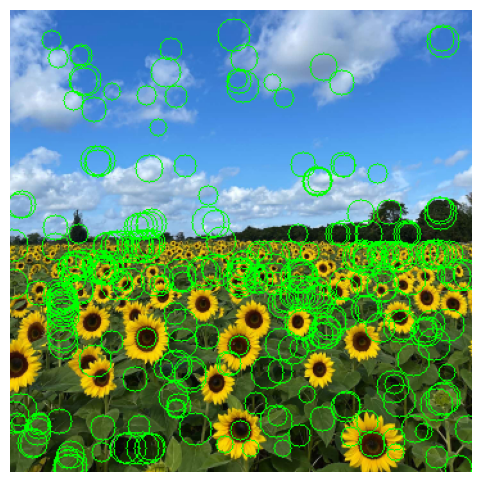

In [47]:
im = cv.imread('Images/the_berry_farms_sunflower_field.jpeg',cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
sigmas = np.linspace(5.0, 10.0, num=15)
scale_space = []
print(f"Range of sigmas: {sigmas}")

for sigma in sigmas:
    ksize = int(2 * np.ceil(3 * sigma) + 1)  # Define kernel size based on sigma
    blur = cv.GaussianBlur(gray, (ksize, ksize), sigma) # Apply Gaussian blur
    lap = cv.Laplacian(blur, cv.CV_32F) # Apply Laplacian operator
    log_response = (sigma ** 2) * np.abs(lap) # Scale-normalized Laplacian response
    scale_space.append(log_response)

scale_space = np.array(scale_space)
detections = []
threshold = 0.02

for s in range(1, len(sigmas) - 1):
    for y in range(1, gray.shape[0] - 1):
        for x in range(1, gray.shape[1] - 1):
            value = scale_space[s, y, x]
            if value < threshold:
                continue
            neighborhood = scale_space[s - 1:s + 2,y - 1:y + 2,x - 1:x + 2]
            if value == np.max(neighborhood):
                detections.append((y, x, s))

output = im.copy()
for y, x, s in detections:
    sigma = sigmas[s]
    r = int(np.sqrt(2) * sigma)
    cv.circle(output, (x, y), r, (0, 255, 0), 1)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


## Q2: Line and Circle Fitting using RANSAC

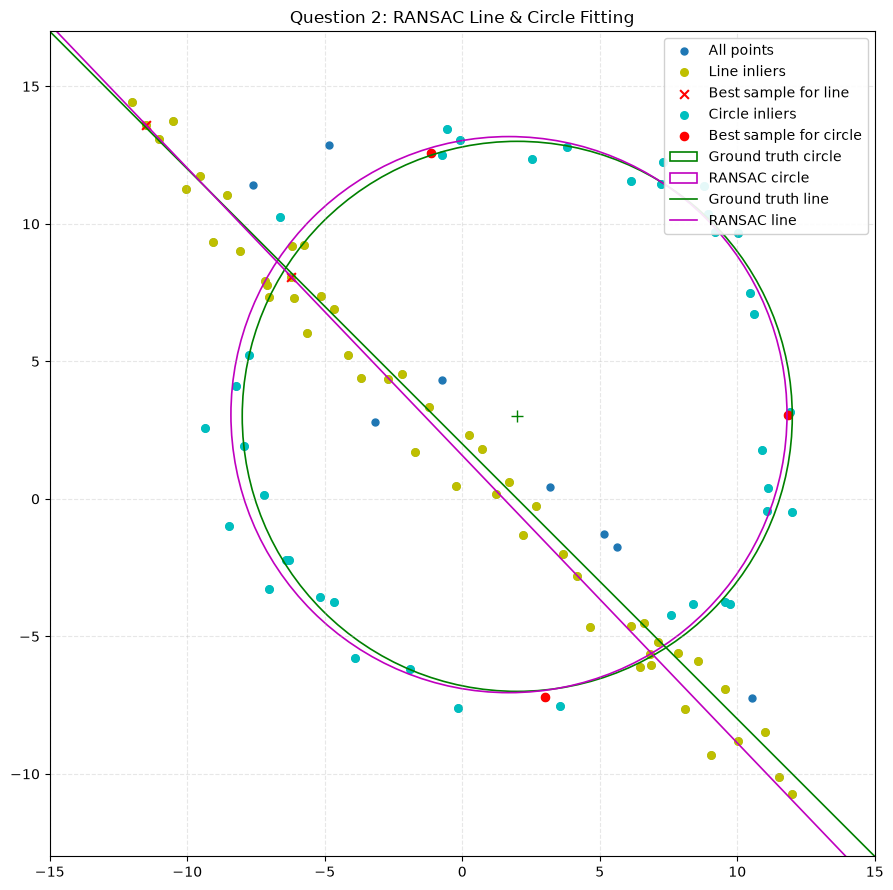

In [48]:

np.random.seed(23)
N = 100
half_n = N // 2

r_gt, x0_gt, y0_gt = 10.0, 2.0, 3.0
s_circ = r_gt / 16.0
t = np.random.uniform(0, 2*np.pi, half_n)
n_circ = s_circ * np.random.randn(half_n)
X_circ = np.column_stack((x0_gt + (r_gt+n_circ)*np.cos(t), y0_gt + (r_gt+n_circ)*np.sin(t)))

s_line, m_gt, b_gt = 1.0, -1.0, 2.0
x_line = np.linspace(-12, 12, half_n)
X_line = np.column_stack((x_line, m_gt*x_line + b_gt + s_line*np.random.randn(half_n)))
X = np.vstack((X_circ, X_line))

def ransac_line(pts, max_iters=1000, thresh=1.0):
    best_inliers, best_sample, best_params = [], None, None
    for _ in range(max_iters):
        idx = np.random.choice(len(pts), 2, replace=False)
        p1, p2 = pts[idx]
        if np.allclose(p1, p2): continue
        dx, dy = p2 - p1
        norm = np.hypot(dx, dy)
        a, b = -dy/norm, dx/norm
        d = -(a*p1[0] + b*p1[1])
        inliers = np.where(np.abs(a*pts[:,0] + b*pts[:,1] + d) < thresh)[0]
        if len(inliers) > len(best_inliers):
            best_inliers, best_sample, best_params = inliers, idx, (a, b, d)
    return best_params, best_sample, best_inliers

line_params, line_sample_idx, line_inlier_idx = ransac_line(X, max_iters=2000, thresh=1.2)
remnant_mask = np.ones(len(X), dtype=bool)
remnant_mask[line_inlier_idx] = False
remnant_indices = np.where(remnant_mask)[0]
X_remnant = X[remnant_mask]

def fit_circle_3pts(p1, p2, p3):
    temp = p2[0]**2 + p2[1]**2
    bc, cd = (p1@p1-temp)/2, (temp-p3@p3)/2
    det = (p1[0]-p2[0])*(p2[1]-p3[1]) - (p2[0]-p3[0])*(p1[1]-p2[1])
    if abs(det) < 1e-6: return None
    cx = (bc*(p2[1]-p3[1])-cd*(p1[1]-p2[1]))/det
    cy = ((p1[0]-p2[0])*cd-(p2[0]-p3[0])*bc)/det
    return cx, cy, np.hypot(p1[0]-cx, p1[1]-cy)

def circle_loss(params, pts):
    cx, cy, rad = params
    return np.sum((np.hypot(pts[:,0]-cx, pts[:,1]-cy)-rad)**2)

def ransac_circle(pts, max_iters=2000, thresh=1.0):
    best_inliers, best_sample, best_circle = [], None, None
    for _ in range(max_iters):
        idx = np.random.choice(len(pts), 3, replace=False)
        circle = fit_circle_3pts(*pts[idx])
        if circle is None: continue
        cx, cy, rad = circle
        inliers = np.where(np.abs(np.hypot(pts[:,0]-cx, pts[:,1]-cy)-rad) < thresh)[0]
        if len(inliers) > len(best_inliers):
            best_inliers, best_sample, best_circle = inliers, idx, circle
    refined = minimize(circle_loss, x0=best_circle, args=(pts[best_inliers],), method='Nelder-Mead')
    return refined.x, best_sample, best_inliers

circle_params, circle_sample_idx, circle_inlier_remnant_idx = ransac_circle(X_remnant, max_iters=2000, thresh=1.0)
circle_inlier_idx = remnant_indices[circle_inlier_remnant_idx]
circle_sample_orig_idx = remnant_indices[circle_sample_idx]

fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(X[:,0], X[:,1], c='#1f77b4', s=25, label='All points')
ax.scatter(*X[line_inlier_idx].T, c='y', s=30, label='Line inliers')
ax.scatter(*X[line_sample_idx].T, c='r', marker='x', s=40, label='Best sample for line')
ax.scatter(*X[circle_inlier_idx].T, c='c', s=30, label='Circle inliers')
ax.scatter(*X[circle_sample_orig_idx].T, c='r', marker='o', s=35, label='Best sample for circle')

ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, color='g', fill=False, linewidth=1.2, label='Ground truth circle'))
ax.plot(x0_gt, y0_gt, '+', color='g', markersize=8)
ax.add_patch(plt.Circle(circle_params[:2], circle_params[2], color='m', fill=False, linewidth=1.2, label='RANSAC circle'))

x_vals = np.array([-15, 15])
ax.plot(x_vals, m_gt*x_vals+b_gt, color='g', linewidth=1.2, label='Ground truth line')
a, b_line, d = line_params
ax.plot(x_vals, (-a*x_vals-d)/b_line, color='m', linewidth=1.2, label='RANSAC line')

ax.set_aspect('equal'); ax.set_xlim(-15, 15); ax.set_ylim(-13, 17)
ax.legend(loc='upper right', framealpha=0.9)
plt.title('Question 2: RANSAC Line & Circle Fitting')
plt.grid(True, linestyle='--', alpha=0.3); plt.tight_layout(); plt.show()


**(d) What will happen if we fit the circle first?**

If we fit the circle first we can see some line points may be incorrectly classified as circle inliers. Then removing these points could reduce the number of line inliers, making the subsequent line fitting less accurate.

## Question 3: Image Homography


Click 4 corners in this order: top-left, top-right, bottom-right, bottom-left.


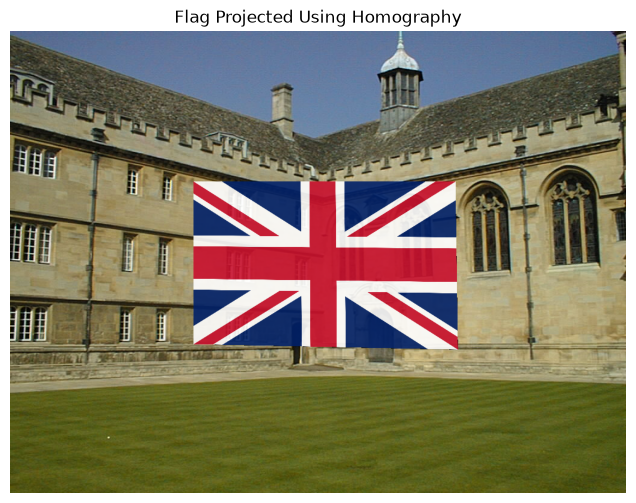

In [49]:
background_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/wadham.jpg")
overlay_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/flag.png")
# background_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/train.jpg")
# overlay_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/sri lanka.jpeg")
# background_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/tokyo.jpeg")
# overlay_bgr = cv.imread("/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/peacock.jpg")
display_img = background_bgr.copy()
points = []

def select_point(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
        points.append([x, y])
        cv.circle(display_img, (x, y), 6, (0, 255, 0), -1)
        cv.putText(
            display_img, str(len(points)), (x + 8, y - 8),
            cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2
        )
        cv.imshow("Select 4 corners", display_img)

cv.namedWindow("Select 4 corners", cv.WINDOW_NORMAL)
cv.imshow("Select 4 corners", display_img)
cv.setMouseCallback("Select 4 corners", select_point)
print("Click 4 corners in this order: top-left, top-right, bottom-right, bottom-left.")

while len(points) < 4:
    if cv.waitKey(20) & 0xFF == 27:  # Esc to cancel
        cv.destroyAllWindows()
        raise RuntimeError("Point selection cancelled.")

cv.destroyAllWindows()

dst_pts = np.float32(points)

h, w = overlay_bgr.shape[:2]
src_pts = np.float32([
    [0, 0],
    [w - 1, 0],
    [w - 1, h - 1],
    [0, h - 1]
])

H = cv.getPerspectiveTransform(src_pts, dst_pts)
warped = cv.warpPerspective(
    overlay_bgr, H,
    (background_bgr.shape[1], background_bgr.shape[0])
)
mask_src = np.full((h, w), 255, dtype=np.uint8)
mask = cv.warpPerspective(
    mask_src, H,
    (background_bgr.shape[1], background_bgr.shape[0])
)
mask = mask > 0

alpha = 0.9 #opacity of the flag (60% flag, 40% background)
result = background_bgr.copy()
result[mask] = cv.addWeighted(background_bgr, 1 - alpha,warped, alpha, 0)[mask]

result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)
plt.figure(figsize=(10, 6))
plt.imshow(result_rgb)
plt.title("Flag Projected Using Homography")
plt.axis("off")
plt.show()


**Rationale for Image Selection:**

Three image pairs were selected: Wadham College with the British flag(provided one), Tokyo with Sri Lankan peacock, and a train with a visit Sri Lankan image. These pairs were chosen to demonstrate how homography can transform and project different images onto selected regions of a background. These images contain flat surfaces and then we can easily project another image.

## Question 4: PCB Image Alignment and Difference Detection


In [50]:
folder = "/home/lasan-perera/University(Aca)/EN3160-assignment-2/Images/pcbs"

reference = cv.imread(os.path.join(folder, "AECC1.jpg"))
reference_gray = cv.cvtColor(reference, cv.COLOR_BGR2GRAY)

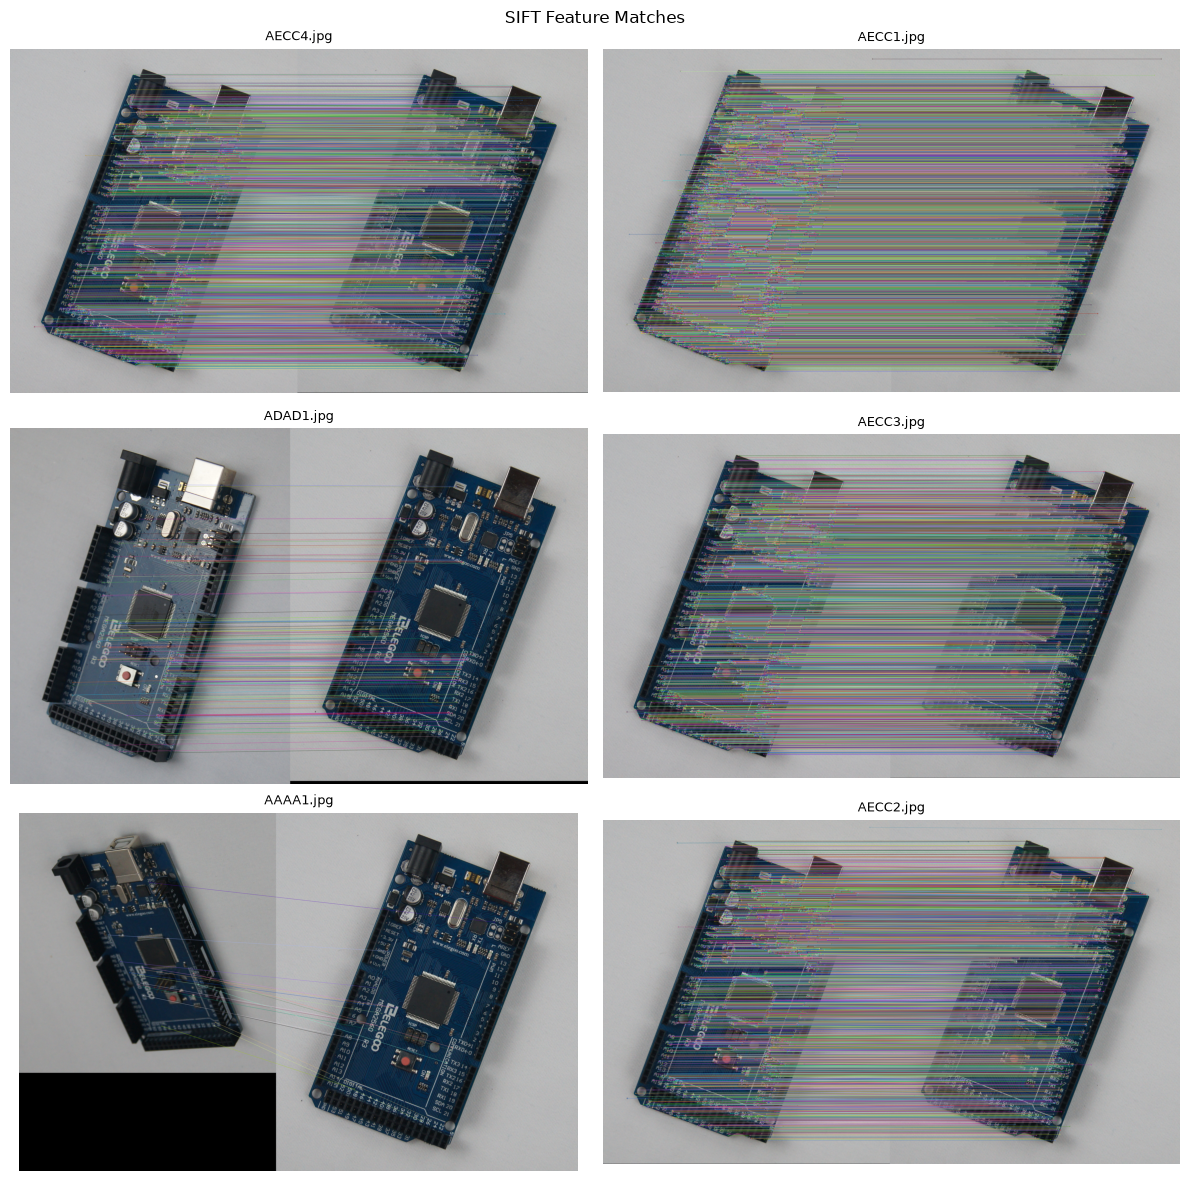

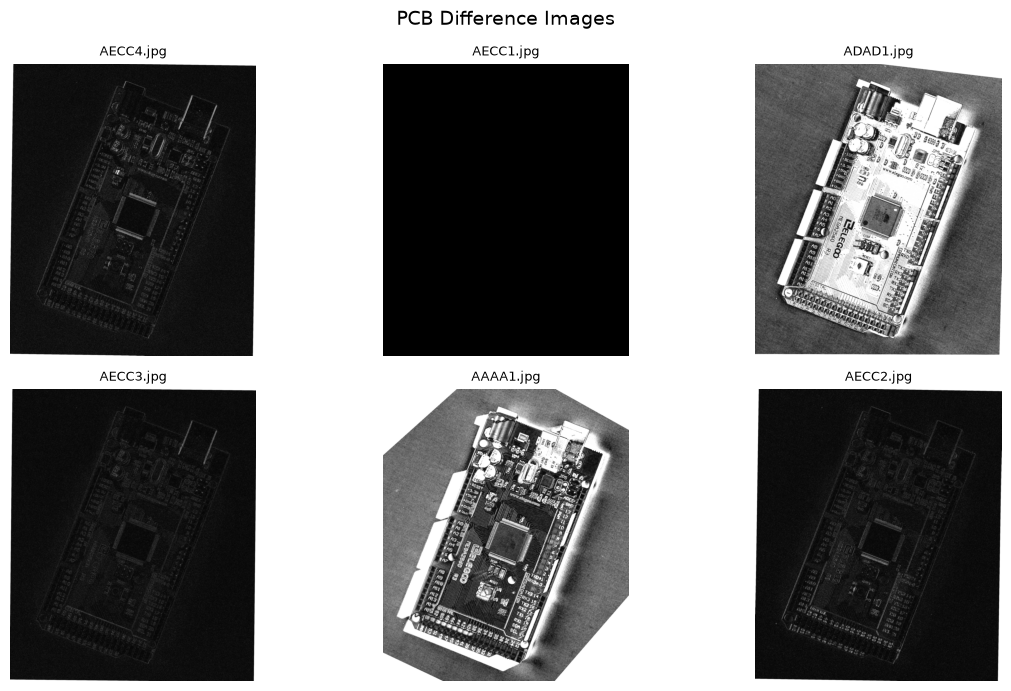

In [51]:
sift = cv.SIFT_create()
kp_ref, des_ref = sift.detectAndCompute(reference_gray, None)
matcher = cv.BFMatcher()

image_paths = glob.glob(os.path.join(folder, "*.jpg"))
difference_images, match_images = [], []

for path in image_paths:
    image = cv.imread(path)
    if image is None: continue

    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    kp_img, des_img = sift.detectAndCompute(gray, None)
    if des_img is None or des_ref is None: continue

    matches = matcher.knnMatch(des_img, des_ref, k=2)
    good = [m for pair in matches if len(pair) == 2 for m, n in [pair] if m.distance < 0.75 * n.distance]
    if len(good) < 4: continue

    src_pts = np.float32([kp_img[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_ref[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, inliers = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)
    if H is None or inliers is None: continue

    match_img = cv.drawMatches(image, kp_img, reference, kp_ref, good, None, matchesMask=inliers.ravel().tolist(), flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    match_images.append((os.path.basename(path), match_img))
    aligned = cv.warpPerspective(image, H, (reference.shape[1], reference.shape[0]))
    difference_images.append((os.path.basename(path), cv.absdiff(reference, aligned)))

n = len(match_images)
if n:
    fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(12, 4 * ((n + 1) // 2)))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, img) in zip(axes, match_images):
        ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)); ax.set_title(name, fontsize=9); ax.axis("off")
    for ax in axes[n:]: ax.axis("off")
    plt.suptitle("SIFT Feature Matches"); plt.tight_layout(); plt.show()

n = len(difference_images)
if n:
    fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(12, 3.5 * ((n + 2) // 3)))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, diff) in zip(axes, difference_images):
        ax.imshow(cv.cvtColor(diff, cv.COLOR_BGR2GRAY), cmap="gray", vmin=0, vmax=50); ax.set_title(name, fontsize=9); ax.axis("off")
    for ax in axes[n:]: ax.axis("off")
    plt.suptitle("PCB Difference Images", fontsize=14); plt.tight_layout(); plt.show()


**(e) Reason for High Differences:**

The USB Type-B port, capacitors, and reset button may show high differences due to variations in component positions, shapes, or sizes(packages) compared with the reference image. Small alignment errors caused by the homography transformation may also contribute to these differences.